In [1]:
from pathlib import Path

# Dataset location
dataset_path = Path(r"C:\Users\HP\Downloads\pcb-defect-dataset")

# Dataset splits
train_path = dataset_path / "train"
val_path = dataset_path / "val"
test_path = dataset_path / "test"

print("Dataset found:", dataset_path.exists())
print("Train folder:", train_path.exists())
print("Validation folder:", val_path.exists())
print("Test folder:", test_path.exists())

Dataset found: True
Train folder: True
Validation folder: True
Test folder: True


In [2]:
# Count images and labels in each dataset split

splits = {
    "Train": train_path,
    "Validation": val_path,
    "Test": test_path
}

for split_name, split_path in splits.items():
    images = list((split_path / "images").glob("*"))
    labels = list((split_path / "labels").glob("*.txt"))

    print(f"{split_name}:")
    print(f"  Images : {len(images)}")
    print(f"  Labels : {len(labels)}")
    print()

Train:
  Images : 8534
  Labels : 8534

Validation:
  Images : 1066
  Labels : 1066

Test:
  Images : 1068
  Labels : 1068



In [3]:
# Check whether every image has a corresponding label file

for split_name, split_path in splits.items():
    image_files = {p.stem for p in (split_path / "images").glob("*")}
    label_files = {p.stem for p in (split_path / "labels").glob("*.txt")}

    missing_labels = image_files - label_files
    missing_images = label_files - image_files

    print(f"{split_name}:")
    print(f"  Images without labels : {len(missing_labels)}")
    print(f"  Labels without images : {len(missing_images)}")
    print()

Train:
  Images without labels : 2164
  Labels without images : 2164

Validation:
  Images without labels : 264
  Labels without images : 264

Test:
  Images without labels : 239
  Labels without images : 239



In [4]:
# Show a few filenames that don't have matching counterparts

for split_name, split_path in splits.items():
    image_files = {p.stem for p in (split_path / "images").glob("*")}
    label_files = {p.stem for p in (split_path / "labels").glob("*.txt")}

    missing_labels = sorted(image_files - label_files)
    missing_images = sorted(label_files - image_files)

    print(f"\n{'=' * 60}")
    print(split_name)
    print(f"{'=' * 60}")

    print("\nImages without matching labels:")
    for name in missing_labels[:10]:
        print(" ", name)

    print("\nLabels without matching images:")
    for name in missing_images[:10]:
        print(" ", name)


Train

Images without matching labels:
  light_01_missing_hole_01_1_600
  light_01_missing_hole_01_2_600
  light_01_missing_hole_02_1_600
  light_01_missing_hole_03_1_600
  light_01_missing_hole_04_1_600
  light_01_missing_hole_04_2_600
  light_01_missing_hole_06_1_600
  light_01_missing_hole_06_2_600
  light_01_missing_hole_08_1_600
  light_01_missing_hole_08_3_600

Labels without matching images:
  light_01_missing_hole_01_1_256
  light_01_missing_hole_01_2_256
  light_01_missing_hole_02_1_256
  light_01_missing_hole_03_1_256
  light_01_missing_hole_04_1_256
  light_01_missing_hole_04_2_256
  light_01_missing_hole_06_1_256
  light_01_missing_hole_06_2_256
  light_01_missing_hole_08_1_256
  light_01_missing_hole_08_3_256

Validation

Images without matching labels:
  light_01_missing_hole_02_2_600
  light_01_missing_hole_03_2_600
  light_01_missing_hole_05_1_600
  light_01_missing_hole_07_2_600
  light_01_missing_hole_09_1_600
  light_01_missing_hole_10_3_600
  light_01_missing_hole_

In [5]:
# Correctly match images and labels by removing their size suffix

for split_name, split_path in splits.items():

    image_files = {
        p.stem.removesuffix("_600")
        for p in (split_path / "images").glob("*")
    }

    label_files = {
        p.stem.removesuffix("_256")
        for p in (split_path / "labels").glob("*.txt")
    }

    missing_labels = image_files - label_files
    missing_images = label_files - image_files

    print(f"{split_name}:")
    print(f"  Images without labels : {len(missing_labels)}")
    print(f"  Labels without images : {len(missing_images)}")
    print()

Train:
  Images without labels : 6370
  Labels without images : 6370

Validation:
  Images without labels : 802
  Labels without images : 802

Test:
  Images without labels : 829
  Labels without images : 829



In [6]:
# Inspect the filename endings used by images and labels

for split_name, split_path in splits.items():

    image_stems = [p.stem for p in (split_path / "images").glob("*")]
    label_stems = [p.stem for p in (split_path / "labels").glob("*.txt")]

    print(f"\n{'=' * 60}")
    print(split_name)
    print(f"{'=' * 60}")

    print("\nLast part of image filenames:")
    for name in image_stems[:15]:
        print(" ", name)

    print("\nLast part of label filenames:")
    for name in label_stems[:15]:
        print(" ", name)


Train

Last part of image filenames:
  light_01_missing_hole_01_1_600
  light_01_missing_hole_01_2_600
  light_01_missing_hole_02_1_600
  light_01_missing_hole_03_1_600
  light_01_missing_hole_04_1_600
  light_01_missing_hole_04_2_600
  light_01_missing_hole_06_1_600
  light_01_missing_hole_06_2_600
  light_01_missing_hole_08_1_600
  light_01_missing_hole_08_3_600
  light_01_missing_hole_09_2_600
  light_01_missing_hole_09_3_600
  light_01_missing_hole_10_2_600
  light_01_missing_hole_11_1_600
  light_01_missing_hole_11_2_600

Last part of label filenames:
  light_01_missing_hole_01_1_256
  light_01_missing_hole_01_2_256
  light_01_missing_hole_02_1_256
  light_01_missing_hole_03_1_256
  light_01_missing_hole_04_1_256
  light_01_missing_hole_04_2_256
  light_01_missing_hole_06_1_256
  light_01_missing_hole_06_2_256
  light_01_missing_hole_08_1_256
  light_01_missing_hole_08_3_256
  light_01_missing_hole_09_2_256
  light_01_missing_hole_09_3_256
  light_01_missing_hole_10_2_256
  light

In [7]:
# Investigate the filename suffixes used in the dataset

for split_name, split_path in splits.items():

    image_stems = [p.stem for p in (split_path / "images").glob("*")]
    label_stems = [p.stem for p in (split_path / "labels").glob("*.txt")]

    image_600 = sum(name.endswith("_600") for name in image_stems)
    label_256 = sum(name.endswith("_256") for name in label_stems)

    print(f"\n{split_name}")
    print("-" * 40)
    print("Total images :", len(image_stems))
    print("Images ending _600 :", image_600)
    print("Total labels :", len(label_stems))
    print("Labels ending _256 :", label_256)

    # Show a few filenames that DON'T have the expected suffix
    unusual_images = [name for name in image_stems if not name.endswith("_600")]
    unusual_labels = [name for name in label_stems if not name.endswith("_256")]

    print("\nUnusual image filenames:", len(unusual_images))
    for name in unusual_images[:10]:
        print(" ", name)

    print("\nUnusual label filenames:", len(unusual_labels))
    for name in unusual_labels[:10]:
        print(" ", name)


Train
----------------------------------------
Total images : 8534
Images ending _600 : 8534
Total labels : 8534
Labels ending _256 : 2164

Unusual image filenames: 0

Unusual label filenames: 6370
  l_light_01_missing_hole_01_1_600
  l_light_01_missing_hole_01_2_600
  l_light_01_missing_hole_02_1_600
  l_light_01_missing_hole_02_2_600
  l_light_01_missing_hole_02_3_600
  l_light_01_missing_hole_03_2_600
  l_light_01_missing_hole_04_1_600
  l_light_01_missing_hole_05_1_600
  l_light_01_missing_hole_05_2_600
  l_light_01_missing_hole_06_1_600

Validation
----------------------------------------
Total images : 1066
Images ending _600 : 1066
Total labels : 1066
Labels ending _256 : 264

Unusual image filenames: 0

Unusual label filenames: 802
  l_light_01_missing_hole_03_1_600
  l_light_01_missing_hole_11_1_600
  l_light_01_missing_hole_11_5_600
  l_light_01_missing_hole_13_2_600
  l_light_01_missing_hole_19_3_600
  l_light_01_mouse_bite_03_1_600
  l_light_01_mouse_bite_05_1_600
  l_ligh

In [8]:
# Correctly match images and labels using the dataset's naming convention

def normalize_image_name(stem):
    # Images end with _600
    return stem.removesuffix("_600")


def normalize_label_name(stem):
    # Labels may start with l_
    if stem.startswith("l_"):
        stem = stem[2:]

    # Labels may end with _256 or _600
    if stem.endswith("_256"):
        stem = stem.removesuffix("_256")
    elif stem.endswith("_600"):
        stem = stem.removesuffix("_600")

    return stem


for split_name, split_path in splits.items():

    image_files = {
        normalize_image_name(p.stem)
        for p in (split_path / "images").glob("*")
    }

    label_files = {
        normalize_label_name(p.stem)
        for p in (split_path / "labels").glob("*.txt")
    }

    missing_labels = image_files - label_files
    missing_images = label_files - image_files

    print(f"{split_name}:")
    print(f"  Images without labels : {len(missing_labels)}")
    print(f"  Labels without images : {len(missing_images)}")
    print()

Train:
  Images without labels : 2106
  Labels without images : 400

Validation:
  Images without labels : 280
  Labels without images : 254

Test:
  Images without labels : 281
  Labels without images : 256



In [9]:
# Find images that contain "l_light" in their filename

for split_name, split_path in splits.items():

    matching_images = [
        p.name
        for p in (split_path / "images").glob("*")
        if "l_light" in p.stem
    ]

    matching_labels = [
        p.name
        for p in (split_path / "labels").glob("*.txt")
        if "l_light" in p.stem
    ]

    print(f"\n{split_name}")
    print("-" * 50)

    print("Images containing 'l_light':", len(matching_images))
    print("Labels containing 'l_light':", len(matching_labels))

    print("\nExample images:")
    for name in matching_images[:10]:
        print(" ", name)

    print("\nExample labels:")
    for name in matching_labels[:10]:
        print(" ", name)


Train
--------------------------------------------------
Images containing 'l_light': 2106
Labels containing 'l_light': 2106

Example images:
  l_light_01_missing_hole_01_1_600.jpg
  l_light_01_missing_hole_01_2_600.jpg
  l_light_01_missing_hole_02_1_600.jpg
  l_light_01_missing_hole_02_2_600.jpg
  l_light_01_missing_hole_02_3_600.jpg
  l_light_01_missing_hole_03_2_600.jpg
  l_light_01_missing_hole_04_1_600.jpg
  l_light_01_missing_hole_05_1_600.jpg
  l_light_01_missing_hole_05_2_600.jpg
  l_light_01_missing_hole_06_1_600.jpg

Example labels:
  l_light_01_missing_hole_01_1_600.txt
  l_light_01_missing_hole_01_2_600.txt
  l_light_01_missing_hole_02_1_600.txt
  l_light_01_missing_hole_02_2_600.txt
  l_light_01_missing_hole_02_3_600.txt
  l_light_01_missing_hole_03_2_600.txt
  l_light_01_missing_hole_04_1_600.txt
  l_light_01_missing_hole_05_1_600.txt
  l_light_01_missing_hole_05_2_600.txt
  l_light_01_missing_hole_06_1_600.txt

Validation
------------------------------------------------

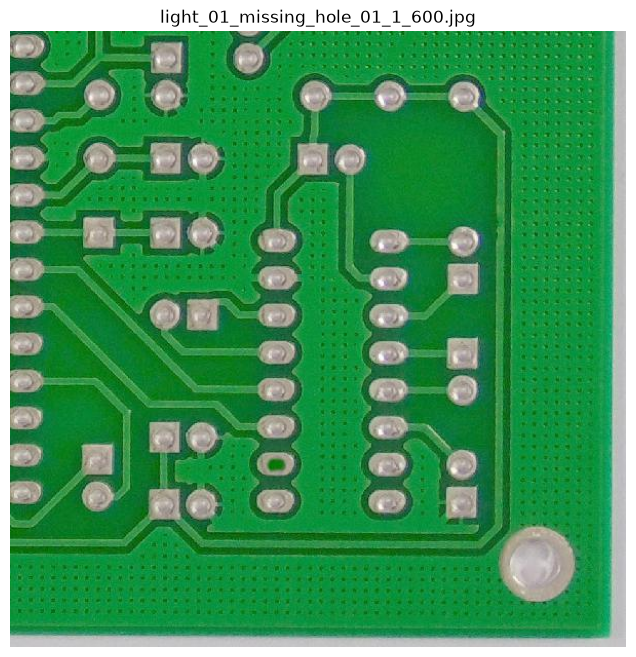

Image path: C:\Users\HP\Downloads\pcb-defect-dataset\train\images\light_01_missing_hole_01_1_600.jpg
Image shape: (600, 600, 3)


In [10]:
import cv2
import matplotlib.pyplot as plt

# Get one image from the training set
image_files = list((train_path / "images").glob("*.jpg"))

image_path = image_files[0]

# Read image
image = cv2.imread(str(image_path))

# OpenCV reads images as BGR, while Matplotlib expects RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display
plt.figure(figsize=(8, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.title(image_path.name)
plt.show()

# Print basic information
print("Image path:", image_path)
print("Image shape:", image.shape)

In [11]:
# Find the label corresponding to the selected image

image_stem = image_path.stem

possible_labels = [
    train_path / "labels" / f"{image_stem}.txt",
    train_path / "labels" / f"{image_stem.removesuffix('_600')}_256.txt",
    train_path / "labels" / f"l_{image_stem}.txt"
]

label_path = None

for path in possible_labels:
    if path.exists():
        label_path = path
        break

print("Image:", image_path.name)

if label_path:
    print("Label:", label_path.name)

    with open(label_path, "r") as f:
        annotations = f.readlines()

    print("\nAnnotations:")
    for annotation in annotations:
        print(annotation.strip())
else:
    print("❌ No matching label found.")

Image: light_01_missing_hole_01_1_600.jpg
Label: light_01_missing_hole_01_1_256.txt

Annotations:
2 0.4350 0.7008 0.0700 0.0550


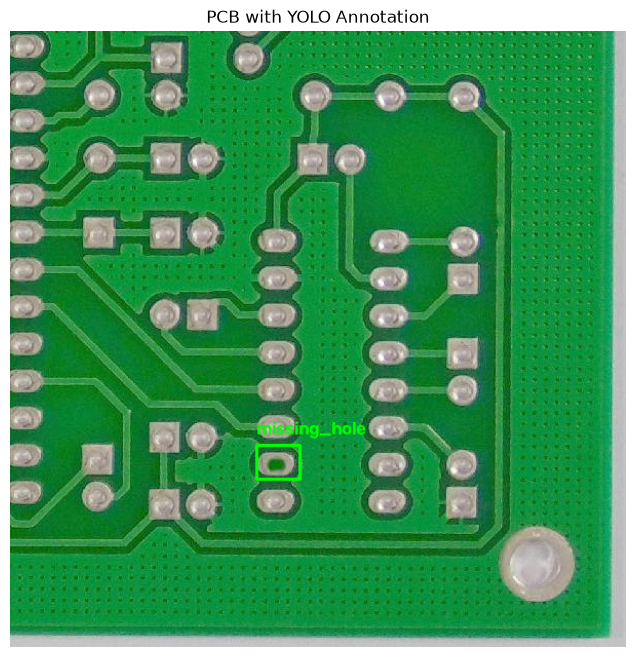

In [12]:
# Draw YOLO bounding boxes on the image

import cv2
import matplotlib.pyplot as plt

# Image dimensions
height, width = image.shape[:2]

# Make a copy so the original image isn't modified
image_with_boxes = image.copy()

# Class names from data.yaml
class_names = {
    0: "mouse_bite",
    1: "spur",
    2: "missing_hole",
    3: "short",
    4: "open_circuit",
    5: "spurious_copper"
}

# Read annotations
with open(label_path, "r") as f:
    annotations = f.readlines()

for annotation in annotations:

    # Convert values from text to numbers
    class_id, x_center, y_center, box_width, box_height = map(
        float, annotation.split()
    )

    class_id = int(class_id)

    # Convert normalized coordinates to pixel coordinates
    x_center *= width
    y_center *= height
    box_width *= width
    box_height *= height

    # Calculate top-left and bottom-right corners
    x1 = int(x_center - box_width / 2)
    y1 = int(y_center - box_height / 2)
    x2 = int(x_center + box_width / 2)
    y2 = int(y_center + box_height / 2)

    # Draw bounding box
    cv2.rectangle(
        image_with_boxes,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    # Add class name
    label = class_names[class_id]

    cv2.putText(
        image_with_boxes,
        label,
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

# Convert BGR → RGB for Matplotlib
image_with_boxes_rgb = cv2.cvtColor(
    image_with_boxes,
    cv2.COLOR_BGR2RGB
)

# Display
plt.figure(figsize=(8, 8))
plt.imshow(image_with_boxes_rgb)
plt.axis("off")
plt.title("PCB with YOLO Annotation")
plt.show()

In [13]:
def find_label(image_path, labels_path):
    stem = image_path.stem

    possible_labels = [
        labels_path / f"{stem}.txt",
        labels_path / f"{stem.removesuffix('_600')}_256.txt",
        labels_path / f"l_{stem}.txt"
    ]

    for label_path in possible_labels:
        if label_path.exists():
            return label_path

    return None


for split_name, split_path in splits.items():

    images_path = split_path / "images"
    labels_path = split_path / "labels"

    images = list(images_path.glob("*.jpg"))

    matched = 0
    unmatched = []

    for image_path in images:
        label_path = find_label(image_path, labels_path)

        if label_path:
            matched += 1
        else:
            unmatched.append(image_path.name)

    print(f"{split_name}:")
    print(f"  Total images : {len(images)}")
    print(f"  Matched      : {matched}")
    print(f"  Unmatched    : {len(unmatched)}")
    print()

Train:
  Total images : 8534
  Matched      : 8534
  Unmatched    : 0

Validation:
  Total images : 1066
  Matched      : 1066
  Unmatched    : 0

Test:
  Total images : 1068
  Matched      : 1068
  Unmatched    : 0



In [14]:
from pathlib import Path

output_file = Path(r"D:\PCB Defect Detection\dataset_file_mapping.txt")

with open(output_file, "w", encoding="utf-8") as f:

    for split_name, split_path in splits.items():

        f.write("=" * 70 + "\n")
        f.write(f"{split_name.upper()}\n")
        f.write("=" * 70 + "\n\n")

        images_path = split_path / "images"
        labels_path = split_path / "labels"

        for image_path in sorted(images_path.glob("*.jpg")):

            label_path = find_label(image_path, labels_path)

            f.write(f"image: {image_path.name}\n")

            if label_path:
                f.write(f"label: {label_path.name}\n")
            else:
                f.write("label: NOT FOUND\n")

            f.write("\n")

print("Mapping saved to:")
print(output_file)

Mapping saved to:
D:\PCB Defect Detection\dataset_file_mapping.txt


In [15]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
class_names = {
    0: "mouse_bite",
    1: "spur",
    2: "missing_hole",
    3: "short",
    4: "open_circuit",
    5: "spurious_copper"
}

class_names

{0: 'mouse_bite',
 1: 'spur',
 2: 'missing_hole',
 3: 'short',
 4: 'open_circuit',
 5: 'spurious_copper'}

In [17]:
class_counts = Counter()

for split_name, split_path in splits.items():
    labels_path = split_path / "labels"

    for label_file in labels_path.glob("*.txt"):
        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) == 5:
                    class_id = int(parts[0])
                    class_counts[class_id] += 1

class_counts

Counter({0: 3684, 5: 3676, 1: 3636, 2: 3612, 4: 3548, 3: 3508})

In [18]:
class_distribution = pd.DataFrame({
    "Class ID": class_counts.keys(),
    "Defect": [class_names[i] for i in class_counts.keys()],
    "Instances": class_counts.values()
})

class_distribution

,Class ID,Defect,Instances
0,2,missing_hole,3612
1,0,mouse_bite,3684
2,4,open_circuit,3548
3,3,short,3508
4,5,spurious_copper,3676
5,1,spur,3636


In [19]:
images_per_class = Counter()

for split_name, split_path in splits.items():
    labels_path = split_path / "labels"

    for label_file in labels_path.glob("*.txt"):
        classes_in_image = set()

        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) == 5:
                    class_id = int(parts[0])
                    classes_in_image.add(class_id)

        for class_id in classes_in_image:
            images_per_class[class_id] += 1

images_per_class

Counter({0: 1852, 2: 1832, 5: 1760, 1: 1752, 4: 1740, 3: 1732})

In [20]:
image_distribution = pd.DataFrame({
    "Class ID": sorted(images_per_class.keys()),
    "Defect": [class_names[i] for i in sorted(images_per_class.keys())],
    "Images Containing Defect": [
        images_per_class[i] for i in sorted(images_per_class.keys())
    ]
})

image_distribution

,Class ID,Defect,Images Containing Defect
0,0,mouse_bite,1852
1,1,spur,1752
2,2,missing_hole,1832
3,3,short,1732
4,4,open_circuit,1740
5,5,spurious_copper,1760


In [21]:
no_defect_images = 0

for split_name, split_path in splits.items():
    labels_path = split_path / "labels"

    for label_file in labels_path.glob("*.txt"):
        with open(label_file, "r") as f:
            lines = [line.strip() for line in f if line.strip()]

        if len(lines) == 0:
            no_defect_images += 1

print("Images with no annotations:", no_defect_images)

Images with no annotations: 0


In [22]:
image_distribution = pd.DataFrame({
    "Class ID": sorted(images_per_class.keys()),
    "Defect": [class_names[i] for i in sorted(images_per_class.keys())],
    "Images Containing Defect": [
        images_per_class[i] for i in sorted(images_per_class.keys())
    ]
})

image_distribution

,Class ID,Defect,Images Containing Defect
0,0,mouse_bite,1852
1,1,spur,1752
2,2,missing_hole,1832
3,3,short,1732
4,4,open_circuit,1740
5,5,spurious_copper,1760


In [23]:
bbox_data = []

for split_name, split_path in splits.items():
    labels_path = split_path / "labels"

    for label_file in labels_path.glob("*.txt"):
        with open(label_file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if len(parts) == 5:
                    class_id = int(parts[0])
                    x_center = float(parts[1])
                    y_center = float(parts[2])
                    width = float(parts[3])
                    height = float(parts[4])

                    bbox_data.append({
                        "split": split_name,
                        "class_id": class_id,
                        "defect": class_names[class_id],
                        "width": width,
                        "height": height
                    })

bbox_df = pd.DataFrame(bbox_data)

bbox_df.head()

,split,class_id,defect,width,height
0,Train,2,missing_hole,0.0700,0.0550
1,Train,2,missing_hole,0.0667,0.0617
2,Train,2,missing_hole,0.0717,0.0600
3,Train,2,missing_hole,0.0667,0.0667
4,Train,2,missing_hole,0.0383,0.0567


In [24]:
bbox_df[["width", "height"]].describe()

,width,height
count,21664.000000,21664.000000
mean,0.050512,0.050497
std,0.020193,0.020256
min,0.015000,0.013300
25%,0.036600,0.035000
50%,0.046600,0.046600
75%,0.060000,0.060000
max,0.196700,0.198300


In [25]:
bbox_df["area"] = bbox_df["width"] * bbox_df["height"]

bbox_df["area"].describe()

count    21664.000000
mean         0.002610
std          0.001755
min          0.000366
25%          0.001506
50%          0.002165
75%          0.003218
max          0.024788
Name: area, dtype: float64

In [26]:
bbox_df.groupby("defect")[["width", "height", "area"]].mean()

,width,height,area
defect,,,
missing_hole,0.048592,0.048611,0.002513
mouse_bite,0.045526,0.045504,0.002068
open_circuit,0.036956,0.036942,0.001420
short,0.061036,0.061015,0.003966
spur,0.053788,0.053756,0.002798
spurious_copper,0.057196,0.057176,0.002918


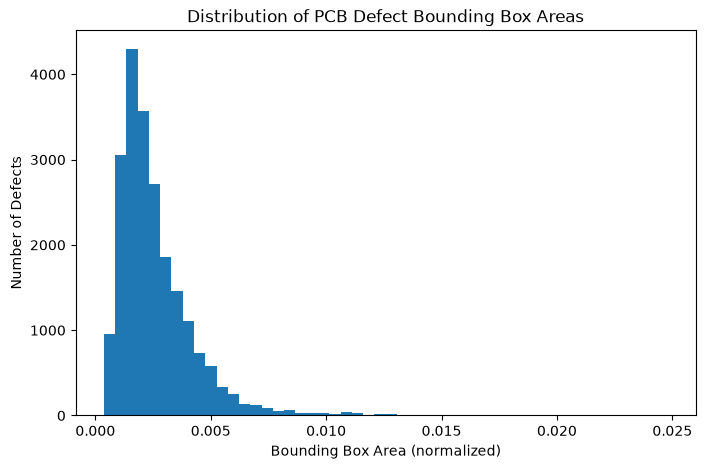

In [27]:
plt.figure(figsize=(8, 5))

plt.hist(bbox_df["area"], bins=50)

plt.xlabel("Bounding Box Area (normalized)")
plt.ylabel("Number of Defects")
plt.title("Distribution of PCB Defect Bounding Box Areas")

plt.show()